In [52]:
# I used GPT-6.1 Sol High Effort to aid me through this introduction to the project

### **Exploring a real protein in UniProt**

Human glycophorin A, P02724.

Imports for sequence and structure visualisation

- **Primary structure:** the amino acid sequence, stored below as `canonical_sequence`.
- **Secondary structure:** local shapes such as alpha helices and beta sheets. A transmembrane helix is an alpha helix that crosses a membrane.
- **Tertiary structure:** the three-dimensional fold of one protein chain.

For our first plot, we will use Matplotlib to mark annotated regions along the sequence, with residue positions starting at 1.

For a 3D view, `py3Dmol` displays atomic coordinates from a structure file such as PDB or mmCIF. It does not predict a fold from the sequence. We will need to obtain an experimental structure or a predicted model, check which part of the sequence it covers, and record its source.

The 3D viewer is optional for this first exercise. If it is missing, run `%pip install "py3Dmol>=2.4,<3"` in a separate cell, then rerun the imports. [Viewer documentation](https://pypi.org/project/py3Dmol/).

In [36]:
import requests  # Download UniProt records or structure files when needed.

# Optional: interactive 3D display of an existing protein structure.
try:
    import py3Dmol
except ModuleNotFoundError as exc:
    if exc.name != "py3Dmol":
        raise
    py3Dmol = None
    print('3D viewer unavailable. For 3D, run %pip install "py3Dmol>=2.4,<3" in a separate cell, then rerun this cell.')

https://www.uniprot.org/uniprotkb/P02724/entry#sequences

P02724-1
This isoform has been chosen as the canonical sequence. All positional information in this entry refers to it. This is also the sequence that appears in the downloadable versions of the entry.

This is the sequence I get when I copy from the website:
MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAHEVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKKSPSDVKPLPSPDTDVPLSSVEIENPETSDQ

Length: 150

Mass (Da): 16,430

In [37]:
canonical_sequence = "MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAHEVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKKSPSDVKPLPSPDTDVPLSSVEIENPETSDQ"
assert len(canonical_sequence) == 150 # check the length is consistent with that is on the website

In [38]:
distinct_amino_acids = set()

for amino_acid in canonical_sequence:
    if amino_acid not in distinct_amino_acids:
        distinct_amino_acids.add(amino_acid)

print(f"The canonical sequnece of PO2724 (PO2724-1) has {len(distinct_amino_acids)} different amino acids.")

The canonical sequnece of PO2724 (PO2724-1) has 18 different amino acids.


UniProt annotates residues 92–114 as a transmembrane helix (that stretch of the chain forms an alpha helix). The subcellular-location annotations have experimental support, as shown in the screenshot. I have not yet established the evidence for the exact region boundaries.

It's membrane-spanning segment starts exactly at residue 92 and ends at 114 (the screenshot does not establish these boundaries however).

The amino acid sequence of the region: **ITLIIFGVMAGVIGTILLISYGI**

In [39]:
canonical_sequence[91:114]

'ITLIIFGVMAGVIGTILLISYGI'

![Alt Text](uniprot-annotation.png)

### **Exploring Model Features**

In [40]:
import os
from pathlib import Path

# Tell InterPLM where to keep its project data.
# Set this before importing its inference functions.
os.environ["INTERPLM_DATA"] = str(Path("data/interplm").resolve())

import numpy as np
import matplotlib.pyplot as plt
import torch

from interplm.embedders import ESM
from interplm.sae.inference import load_sae_from_hf

#### Obtain ESM-2's representations of the sequence

In [41]:
# start with the small, 8-million-parameter model and layer 4 - this layer is an exploratory starting choice
layer = 4

esm_model = ESM(
    model_name="facebook/esm2_t6_8M_UR50D", # publisher / model name (facebook is the publisher’s organisation name on HF)
    device="cpu",
)

# runs the protein sequence through ESM-2 and returns a numerical representation of each residue
# 1. converts the amino acid letters into tokens
# 2. passes the sequence through the pretrained model
# 3. extracts the representation of each residue from layer 4
# 4. removes the special start/end tokens and returns a NumPy array
embeddings = esm_model.embed_single_sequence(
    canonical_sequence,
    layer=layer,
)

print(type(embeddings))
# 150 rows - one per resiude
# 320 columns - the numbers forming that residue's representation (its embedding)
print(embeddings.shape)

<class 'numpy.ndarray'>
(150, 320)


In [42]:
embeddings[91]  # 320 numbers representing residue 92

array([-9.3358642e-01, -8.0633408e-01,  5.1583183e-01, -9.9388987e-01,
       -1.9776751e+00,  4.7068715e-02,  2.4175103e+00,  8.6691421e-01,
        9.0810591e-01, -3.8580641e-01,  4.8921299e-01, -2.1565115e-01,
        3.1727481e-01,  1.1866407e+00,  3.7385786e-01, -2.8003949e-01,
        1.0707070e+00, -1.0462997e+00,  1.4252861e+00, -1.5004587e-01,
       -2.0068902e-01,  5.3337020e-01,  1.0667768e+00, -9.9115729e-01,
        3.2685205e-01,  1.5829726e+00, -1.5051550e+00, -3.4519398e-01,
        1.7737707e+00, -5.0717974e-01, -4.4982725e-01,  1.2897170e-01,
       -4.2492944e-01,  3.4333855e-02, -2.3126793e-01,  2.4619406e-01,
        2.0066029e-01,  1.0178955e+00,  4.3009603e-01,  4.7853261e-01,
        1.8256438e+00,  5.8453554e-01, -6.1315548e-01, -7.1373338e-01,
        1.7393016e+00, -3.7374294e-01,  5.8695376e-01, -6.0531664e-01,
        1.9350486e+00, -1.5226839e+00,  4.3831527e-01,  2.4088764e+00,
        1.4149704e+00, -1.5141047e+00, -1.6943910e+00,  1.1088859e+00,
      

In [43]:
# each embedding depends on the surrounding sequence
# so two identical amino acids at different positions can have different embeddings
# these are internal model representations

# layer-4 embedding describes how ESM-2 represents that residue in its particular sequence context after four transformer layers

#### Convert representations into feature activations

In [44]:
# load the pretrained sparse autoencoder (sae) - this is an InterPLM autoencoder
# the autoencoder must match the ESM-2 model and layer used above
sae = load_sae_from_hf(
    plm_model="esm2-8m",
    plm_layer=layer,
)
sae = sae.to("cpu").eval() # switch the sae to evaluation mode - apply its learned parameters

with torch.inference_mode(): # runs the indented code without tracking gradients - we aren't training here

    # calculates activations for a specified subset of the sae's features
    # the method supports selecting a subset - here we request all features
    activations = sae.encode_feat_subset(
        torch.as_tensor(embeddings, dtype=torch.float32),
        list(range(sae.dict_size)), # sae.dict_size is the number of learned features
        normalize_features=True, # divide each feature's activation by its scaling factor
    ).cpu().numpy()

print(activations.shape)

Loading configs from /Users/ishanmitra/.cache/huggingface/hub/models--Elana--InterPLM-esm2-8m/snapshots/81d2429cd9dae7175f1dcd8b4c649a20cdc06c8c/layer_4/config.yaml
Loaded data type: <class 'interplm.train.configs.TrainingRunConfig'>
Data keys: Not a dict
(150, 10240)


One residue -> 320 embedding values -> 10,240 SAE feature activations

#### Plot one active feature alongside the annotation

In [45]:
# calculating the largest activation value

max_of_each_residue = []
for i in range(150):
    max_of_each_residue.append(max(activations[i]))

max(max_of_each_residue) # this is the strongest activation

0.8359667

In [46]:
# find each feature's largest activation across all 150 residues
feature_peaks = activations.max(axis=0)  # 10,240 values

# find which feature has the largest peak
feature_id = int(feature_peaks.argmax()) # 5712 - argmax returns the index where the largest activation occurs

print(f"Feature ID: {feature_id}") # feature id associated with the largest/strongest activation

positions = np.arange(1, len(canonical_sequence) + 1) # remember len(canonical_sequence) = 150

Feature ID: 5712


In [49]:
# feature 5712's response at residue 57
activations[56, 5712]

0.8359667

In [51]:
# feature 5712's response at residue 57
# activations[:, 5712] - we plot this below

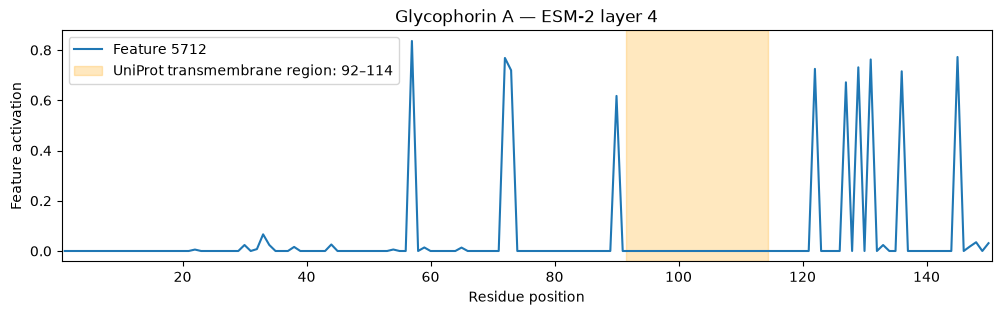

In [47]:
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(positions, activations[:, feature_id],
        label=f"Feature {feature_id}")

ax.axvspan(91.5, 114.5, color="orange", alpha=0.25,
           label="UniProt transmembrane region: 92–114")

ax.set(
    xlabel="Residue position",
    ylabel="Feature activation",
    title=f"Glycophorin A — ESM-2 layer {layer}",
    xlim=(0.5, len(canonical_sequence) + 0.5),
)
ax.legend()
plt.show();

Quick terminology reminder!

- **Activations:** Numbers measuring how strongly each SAE feature responds at each residue.
- **Embeddings:** The 320-number vectors ESM-2 produces at your chosen layer, one per residue, incorporating sequence context.
- **Representations:** A general term for how a model encodes information numerically (embeddings are an instance of representations).

So we have an embeddings array with shape (150, 320) - each amino acid residue has a 320-length vector embedding vector (the embedding dim of the EMS-2 model). We then multiply 320 input dimensions by 32 (the ESM-2 creators chose an expansion factor of 32) to get 320 * 32 = 10,240 SAE feature activation, PER residue. So, we arrive at an activations array of shape (150, 10,240).

#### Evidence-assisted explanation

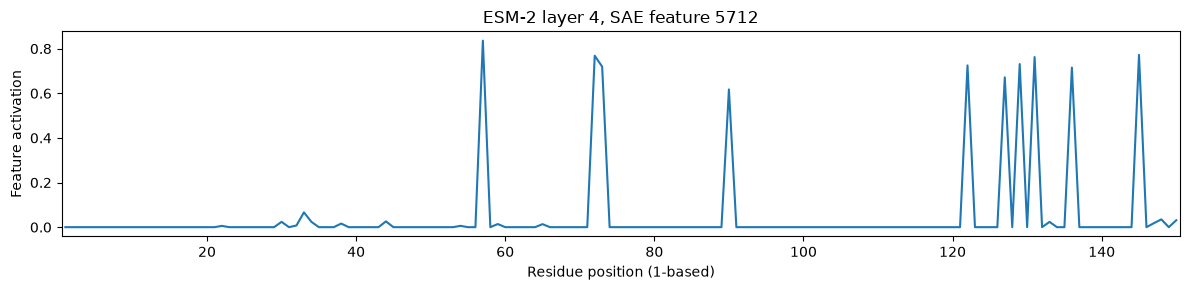

Attach this image in a fresh chat: /Users/ishanmitra/Interpreting-Protein-Language-Models-with-Biological-Evidence/outputs/explanation_exercise/activation_plot.png
The prompt is also saved at: /Users/ishanmitra/Interpreting-Protein-Language-Models-with-Biological-Evidence/outputs/explanation_exercise/prompt_without_evidence.txt
Paste the following prompt into that chat:

The attached plot shows one sparse autoencoder (SAE) feature's
activations for a protein sequence, using ESM-2-8M layer 4,
feature ID 5712. Residue positions start at 1.

Sequence (150 residues):
MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAHEVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKKSPSDVKPLPSPDTDVPLSSVEIENPETSDQ

Describe where the feature activates strongly and weakly.
What biological property, if any, might this feature respond to?

Separate direct observations from hypotheses. Explain what the
available information cannot establish and suggest one way to test
your interpretation acro

In [48]:
# Run after calculating activations and choosing feature_id.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

llm_output_dir = Path("outputs/explanation_exercise")
llm_output_dir.mkdir(parents=True, exist_ok=True)
llm_plot_path = llm_output_dir / "activation_plot.png"
llm_prompt_path = llm_output_dir / "prompt_without_evidence.txt"

# Use a new figure with residue positions and activations only.
llm_positions = np.arange(1, len(canonical_sequence) + 1)
llm_fig, llm_ax = plt.subplots(figsize=(12, 3))
llm_ax.plot(llm_positions, activations[:, feature_id])
llm_ax.set(
    xlabel="Residue position (1-based)",
    ylabel="Feature activation",
    title=f"ESM-2 layer {layer}, SAE feature {feature_id}",
    xlim=(0.5, len(canonical_sequence) + 0.5),
)
llm_fig.tight_layout()
llm_fig.savefig(llm_plot_path, dpi=200, bbox_inches="tight")
plt.show()

llm_prompt = f"""The attached plot shows one sparse autoencoder (SAE) feature's
activations for a protein sequence, using ESM-2-8M layer {layer},
feature ID {feature_id}. Residue positions start at 1.

Sequence ({len(canonical_sequence)} residues):
{canonical_sequence}

Describe where the feature activates strongly and weakly.
What biological property, if any, might this feature respond to?

Separate direct observations from hypotheses. Explain what the
available information cannot establish and suggest one way to test
your interpretation across additional proteins.

If a source is supplied below, cite it where relevant.
Do not browse or invent references. Keep your answer under 200 words.

Sources:
None supplied.
"""
llm_prompt_path.write_text(llm_prompt, encoding="utf-8")

print(f"Attach this image in a fresh chat: {llm_plot_path.resolve()}")
print(f"The prompt is also saved at: {llm_prompt_path.resolve()}")
print("Paste the following prompt into that chat:\n")
print(llm_prompt)

I used **Claude Opus 5.5 Extra Effort** as the LLM to run these experiments on.

**Non-RAG Run**:

Direct observations

All 10 prolines activate strongly, at about 0.6–0.84: P57, P72–P73, P90, P122, P127, P129, P131, P136 and P145. P57 is highest (about 0.83) and P90 is lowest (about 0.62).
No other residue rises above about 0.07. A faint signal (0.07 or less) appears in the S/T-rich stretch at residues 30–45 and near the C-terminus.
Residues 1–56 and the hydrophobic segment at about 92–113 show no activation, and neither region contains a proline.

Hypotheses

The simplest reading is that the feature detects proline itself, not a higher-level biological property.
The differences in peak height might come from context: the S/T-P motifs at 56–57, 121–122 and 130–131, or the proline-rich C-terminal tail. This is speculative.

What this cannot establish
A single sequence cannot show that the feature fires on prolines in general, or that it never fires elsewhere. Nor can it show whether the feature encodes structure (for example polyproline II helix or disorder) rather than just the residue. The values are read off a plot. Nothing here shows that the model actually relies on this feature.

Test
Run the SAE across a large, diverse set of proteins. Measure precision and recall for prolines, relate peak height to context annotations, and check whether substituting proline with alanine (P→A) removes the activation.

Non-RAG Run:

Mark - **82%** (manual assessment)

Explanation - Correctly links the strong peaks to prolines, acknowledges uncertainty and proposes a useful validation test. Loses marks for claiming residues 1–56 have no activation despite small visible signals, and for exceeding the 200-word limit.



**RAG Run**

Direct observations

There are ten sharp peaks (≈0.62–0.84), at residues 57, 72, 73, 90, 122, 127, 129, 131, 136 and 145. These are exactly the sequence’s ten prolines; I matched each position to its residue in code.
There is faint signal (≤≈0.07) in the Ser/Thr-rich stretch at 30–44 and near 146–150. Elsewhere the activation is zero.
The feature is silent across 92–114, which is annotated as a helical transmembrane region [U1]. This assumes the given sequence is the P02724 canonical sequence. That segment contains no prolines.

Hypothesis
The feature most likely detects proline itself, which fits an early layer of a small model. Any link to loops, disorder or polyproline II helices is untested. The silence over the transmembrane region follows from its composition, so it says nothing about membrane context.

What cannot be established

Whether context changes peak height.
Whether other residues activate strongly in other proteins.
What causal role the feature plays in the model.
Whether the pattern holds beyond one protein.

All values are read off the plot, not raw data.

Test
Across several thousand diverse proteins, compute precision and recall of “activation > 0.3” against “residue is proline”. Near-perfect agreement would confirm a proline detector. Then regress activation strength at prolines on context (disorder, secondary structure, neighbouring residues).

RAG Run:

Mark - **76%** (manual assessment)

Explanation - Correctly identifies the proline-associated pattern and cites the transmembrane annotation. Loses marks for unsupported reasoning about an early layer, treating composition as the established cause of inactivity, claiming the proposed test would confirm a proline detector, and exceeding the 200-word limit.



### More in depth: embeddings, SAE features, and activations

Cell generated by *GPT-6.1 Sol High Effort*

(we briefly gave definitions before - here is a more in depth explanation)

I am also starting to appreciating the parallels between PLMs and LLMs.

**Note this is for my benefit/learning!**

An **embedding** is ESM-2's contextual numerical representation of a residue: here, a vector of 320 numbers from layer 4. Its values depend on the residue and its sequence context. **Representation** is the broader term for such an encoding.

A **feature** is a learned component of the sparse autoencoder (SAE), with weights that make it respond to particular patterns in those embeddings. A **feature ID** is its index within this specific SAE; biological meanings are hypotheses we investigate afterwards.

The SAE was trained on the embeddings produced by the particular PLM and layer.

During its original training:
1. Many protein sequences were passed through ESM-2-8M.
2. Their layer-4 embeddings were collected.
3. The SAE learned to reconstruct those embeddings using relatively few active features.

ESM-2’s weights stayed fixed while the SAE learned its own weights.

In this notebook, we apply the pretrained SAE to glycophorin A’s embeddings.

For residue $i$ and feature $j$, the activation in our ReLU SAE can be written as

$$
a_{ij} = \frac{\max\!\left(0,\;\sum_{k=1}^{320} w_{jk}(\tilde{x}_{ik}-c_k)+b_j\right)}{s_j}.
$$

Here, $\tilde{x}_i$ is the embedding after any configured input normalisation; $w_{jk}$ are learned feature weights; $c$ is a learned centring vector; $b_j$ is a learned feature offset; and $s_j$ is the stored feature scale used by `normalize_features=True`. The weighted sum combines the embedding values, `max(0, ...)` sets negative scores to zero, and division rescales the result.

Explicitly, the weighted sum for residue $i$ and feature $j$ is

$$
u_{ij} = \sum_{k=1}^{320} w_{jk}(\tilde{x}_{ik}-c_k)
= w_{j1}(\tilde{x}_{i1}-c_1) + w_{j2}(\tilde{x}_{i2}-c_2) + \cdots + w_{j,320}(\tilde{x}_{i,320}-c_{320}).
$$

Each centred embedding value is multiplied by its learned weight, and the 320 products are added together. The offset is then added to give $u_{ij}+b_j$, so the final activation is $a_{ij}=\max(0,u_{ij}+b_j)/s_j$.

- **Activation:** how strongly feature $j$ responds at residue $i$; it is not a probability or proof of a causal role.
- **Size:** this SAE has $320 \times 32 = 10{,}240$ features, IDs 0–10,239. The same features are evaluated at every residue, giving our array shape `(150, 10240)`.
- **Sparsity:** training encouraged reconstruction of embeddings using relatively few active features; multiple features can still activate at one residue.
- **Plot:** `activations[:, 5712]` gives feature 5712's response across the sequence; `activations[56, 5712]` is its response at residue 57.

**Our current interpretation:** feature 5712's large peaks align with the ten prolines in glycophorin A. This supports a proline-associated hypothesis to test on other proteins. Glycophorin A is the protein being analysed, not an established meaning of the feature.
